# Drones, imagens de altíssima resolução e embeddings

Nesta aula vamos entender onde conseguimos utilizar imagens de drones gratuitas, manipulá-las e fazer seu processamento para o treino. Em seguida, vamos extrair seus embeddings com algum modelo e visualiza-los em nosso notebook. 

Seguindo, os seguintes passos:
1. **Dados**: Imagens abertas de drone do OpenAerialMap.
2. **Resolução**: Padronização da resolução espacial.
3. **Tiling**: cortar as imagens em pedaços (azulejos) e alinhar os rótulos.
4. **Dataset**: organizar os azulejos em uma ferramenta para gerenciamento de datasets visados a visão computacional.
5. **Embeddings**: Utilizar um modelo de deep learning (DINOv2) para transformar cada azulejo em um vetor.
6. **Análises**: reduzir dimensões para visualizar, medir similaridade, agrupar e medir unicidade.


Este notebook está preparado para ser rodado localmente e também em provedores cloud como o `Google Colab`. Avisamos que se for rodar localmente talvez o modelo demore para calcular as inferências. 


**Como rodar**

- **No seu computador:** dentro da pasta do projeto, rode `uv sync` e depois `uv run jupyter lab`, e abra este notebook.
- **No Google Colab:** abra o notebook no Colab e preencha o `REPO_URL` na célula de configuração. 

## Configuração do ambiente

No Colab o projeto ainda não existe, então a configuração clona o repositório e instala as bibliotecas que o Colab não tem. No seu computador, a célula só confirma que estamos na pasta certa.

In [ ]:
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

REPO_URL = "https://github.com/emanuel-gf/FTL-Embeddings-Drones.git"  # preencha com o link do repositório
REPO_DIR = Path("/content/webinar-DL")

if IN_COLAB:
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
    os.chdir(REPO_DIR)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q","duckdb", "fiftyone", "geobr",
                    "pystac-client", "folium", "transformers", "tqdm", "anywidget"], check=True)

ROOT = Path.cwd()
assert (ROOT / "src").is_dir(), f"Pasta do projeto não encontrada em {ROOT}. Abra o notebook dentro de webinar-DL."
sys.path.insert(0, str(ROOT))

print("Pasta do projeto (ROOT):", ROOT)
print("Rodando no Google Colab:", IN_COLAB)

Pasta do projeto (ROOT): /Users/macuser/Documents/UN/projects/webinar-DL
Rodando no Google Colab: False


In [111]:
import fiftyone as fo
fo.__version__

'1.22.1'

In [2]:
import json
import random
import time
from collections import Counter

import folium
import fiftyone as fo
import geobr
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import pystac_client
import requests
import rasterio
import rasterio.shutil
import torch
from PIL import Image
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject, transform_bounds
from rasterio.windows import Window
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import AutoImageProcessor, AutoModel

from src.active_learning import compute_clustering, compute_uniqueness_field, compute_uniqueness_field_v2
from src.annotations import index_with_paths, read_tile_samples
from src.tiler import ground_resolution_m, tile_cogs

W1112 16:17:53.472000 91314 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


# Reinicie sua sessao no colab! Antes de prosseguir.

## 1. Dados

### Como conseguimos as imagens de drone?

As imagens vêm do **OpenAerialMap (OAM)**, um catálogo aberto de imagens aéreas de alta resolução mantido pela HOT (Humanitarian OpenStreetMap Team). Pessoas e contribuidores que trabalham com drone contribuem para o repositório. Qualquer pessoa pode contribuir para as imagens, facilitando a troca e experiência. O propósito do OAM e da HOT, é treinar modelos que ajudam em desastres humanitários, como por exemplo o último terremoto na Venezuela. 

Dentro do catálogo, cada imagem de drone vira um **item** com um identificador (*item ID*) e uma **licença** de uso.

**[Open Aerial Map](https://openaerialmap.org/)**

Para nossa aula de hoje, vamos utilizar a cidade de **São Bento do Una (PE)**, as quais algum bom samaritano mapeou grande parte da cidade. 

### Conectar com a API do STAC

Para acessar as imagens, existem diversas formas. Hoje, vamos utilizar um catálogo que é bastante inovador e vem ganhando força no ecossitema geoespacial: **STAC** (*SpatioTemporal Asset Catalog*). STAC é um padrão para catalogar imagens de observação da Terra, fazendo com que cada **item** seja uma cena (uma imagem), atribuido a metadados como data, sensor, licença e resolução, e cada **asset** é um arquivo (a imagem em si).

Link do STAC do OAM: https://api.imagery.hotosm.org/stac/

In [3]:
STAC_API = "https://api.imagery.hotosm.org/stac/"
COLLECTION = "openaerialmap"

# Pastas do projeto 
COG_DIR = ROOT / "data" / "cog"                # imagens nativas, cerca de 5 cm por pixel
COG10_DIR = ROOT / "data" / "cog_10cm"         # mesmas imagens reamostradas para 10 cm
LABELS_DIR = COG10_DIR / "geojson_labelling"   # labels feitos antes da aula 
STAC_DIR = ROOT / "data" / "stac"              # metadados STAC de cada item
META_DIR = ROOT / "data" / "metadata"          # tabela de metadados e licenças
for folder in (COG_DIR, STAC_DIR, META_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# IDs das imagens que vamos usar nesta aula
ITEM_IDS = [
    "68c41fddae0fc8076633a74e",
    "68a78c9e27e991e401df2876",
    "68a78cb427e991e401df28a2",
    "68a78ce127e991e401df2956",
    "68a78caf27e991e401df289b",
    "68a78d0527e991e401df29cc",
    "685740b9e319ef725278cb92",
    "685740c7e319ef725278cbcf",
    "685740ade319ef725278cb5a",
    "685740c3e319ef725278cbc1",
    "68a4a953e50784296730bf0f",
    "68a5bc60e5584a0f62bfa185",
    "68a5bc63e5584a0f62bfa195",
    "68a5bc16e5584a0f62bfa08c",
    "68a5bc04e5584a0f62bfa047",
    "68a5bc70e5584a0f62bfa1ce",
    "68a5bc31e5584a0f62bfa0ff",
]
print(f"{len(ITEM_IDS)} imagens (IDs únicos)")
print("Imagens nativas:          ", COG_DIR)
print("Imagens em 10 cm:         ", COG10_DIR)
print("Rótulos (entrada da aula):", LABELS_DIR)

17 imagens (IDs únicos)
Imagens nativas:           /Users/macuser/Documents/UN/projects/webinar-DL/data/cog
Imagens em 10 cm:          /Users/macuser/Documents/UN/projects/webinar-DL/data/cog_10cm
Rótulos (entrada da aula): /Users/macuser/Documents/UN/projects/webinar-DL/data/cog_10cm/geojson_labelling


In [4]:
client = pystac_client.Client.open(STAC_API)
collection = client.get_collection(COLLECTION)
print("Coleção:", collection.id, collection.title or "")
collection

Coleção: openaerialmap OpenAerialMap (OAM) STAC Catalog


<CollectionClient id=openaerialmap>

### Acessando os metadados de cada imagem

Para cada ID pedimos ao STAC o item correspondente e guardamos uma cópia local do seu JSON, para não depender da internet depois.

In [5]:
items = {}
for item_id in tqdm(ITEM_IDS, desc="Buscando itens no STAC"):
    item = collection.get_item(item_id)
    items[item_id] = item
    (STAC_DIR / f"{item_id}.json").write_text(json.dumps(item.to_dict(), indent=2))

print(f"{len(items)} itens recuperados; JSON salvos em {STAC_DIR.relative_to(ROOT)}/")

Buscando itens no STAC:   0%|          | 0/17 [00:00<?, ?it/s]

17 itens recuperados; JSON salvos em data/stac/


### Download das imagens

As imagens são **COG** (*Cloud-Optimized GeoTIFF*): um GeoTIFF organizado em blocos, que pode ser lido aos pedaços pela internet. O download é feito em partes (*streaming*), e arquivos que já existem com o tamanho certo são pulados.

In [6]:
def download_cog(url: str, dest: Path, expected_size: int | None = None) -> str:
    # Baixa um COG para o disco. Devolve 'skipped', 'downloaded' ou 'failed'.
    if dest.exists() and expected_size and dest.stat().st_size == expected_size:
        return "skipped"
    try:
        with requests.get(url, stream=True, timeout=120) as r:
            r.raise_for_status()
            total = int(r.headers.get("content-length", 0)) or expected_size
            tmp = dest.with_suffix(".part")
            with open(tmp, "wb") as f, tqdm(
                total=total, unit="B", unit_scale=True, unit_divisor=1024,
                desc=dest.name, leave=False,
            ) as bar:
                for chunk in r.iter_content(chunk_size=1024 * 1024):
                    f.write(chunk)
                    bar.update(len(chunk))
            tmp.rename(dest)
        return "downloaded"
    except requests.RequestException as err:
        print(f"Falhou {dest.name}: {err}")
        return "failed"

status = {}
for item_id, item in tqdm(items.items(), desc="Imagens"):
    asset = item.assets["visual"]
    dest = COG_DIR / f"{item_id}.tif"
    expected = asset.extra_fields.get("file:size")
    status[item_id] = download_cog(asset.href, dest, expected)

print(dict(Counter(status.values())))

Imagens:   0%|          | 0/17 [00:00<?, ?it/s]

{'skipped': 17}


In [7]:
# Conferindo o que foi salvo no disco
rows = []
for item_id in ITEM_IDS:
    path = COG_DIR / f"{item_id}.tif"
    rows.append({
        "item_id": item_id,
        "existe": path.exists(),
        "tamanho_MB": round(path.stat().st_size / 1e6, 1) if path.exists() else None,
    })

summary = pd.DataFrame(rows)
display(summary)
print(f"Total em disco: {summary['tamanho_MB'].sum():.1f} MB em {COG_DIR.relative_to(ROOT)}/")

,item_id,existe,tamanho_MB
0,68c41fddae0fc8076633a74e,True,21.9
1,68a78c9e27e991e401df2876,True,7.4
2,68a78cb427e991e401df28a2,True,13.8
3,68a78ce127e991e401df2956,True,8.8
4,68a78caf27e991e401df289b,True,19.8
5,68a78d0527e991e401df29cc,True,8.1
6,685740b9e319ef725278cb92,True,21.5
7,685740c7e319ef725278cbcf,True,11.5
8,685740ade319ef725278cb5a,True,8.0
9,685740c3e319ef725278cbc1,True,6.9


Total em disco: 223.4 MB em data/cog/


Vejam que as imagens de drone estão nesse formato `COG`. 

Para quem tem curiosidade de entender melhor o que é o formato COG, aqui um artigo excelente:

[O que são COGs?](https://guide.cloudnativegeo.org/cloud-optimized-geotiffs/intro.html)

## 2. Exploratory Data Analysis (EDA): explorar os metadados e entender as condições

### O que é a resolução espacial (GSD)?

O **GSD** (*Ground Sample Distance*) é o tamanho, no chão, de um pixel. Um GSD de 5 cm significa que cada pixel representa um quadrado de 5 × 5 cm do terreno. **Quanto menor o GSD, mais detalhe** a imagem tem.

A função `ground_resolution_m` (do arquivo `src/tiler.py`) calcula esse tamanho em metros a partir da transformação afim (*affine transform*) do arquivo. Ela já lida com CRS geográficos (graus), convertendo para metros.

In [8]:
cogs = sorted(COG_DIR.glob("*.tif"))
print(f"{len(cogs)} arquivos COG encontrados em {COG_DIR.relative_to(ROOT)}/")

17 arquivos COG encontrados em data/cog/


In [9]:
rows = []
for tif in cogs:
    item_id = tif.stem
    stac_props = json.loads((STAC_DIR / f"{item_id}.json").read_text())["properties"]

    with rasterio.open(tif) as src:
        gsd_x, gsd_y = ground_resolution_m(src)
        west, south, east, north = transform_bounds(src.crs, "EPSG:4326", *src.bounds)
        w, h = src.width, src.height

        rows.append({
            "item_id": item_id,
            "producer": stac_props.get("oam:producer_name"),
            "instrument": ", ".join(stac_props.get("instruments", [])),
            "platform": stac_props.get("oam:platform_type"),
            "license": stac_props.get("license"),
            "captured_start": stac_props.get("start_datetime"),
            "captured_end": stac_props.get("end_datetime"),
            "uploaded": stac_props.get("created"),
            "crs": src.crs.to_string(),
            "width_px": w,
            "height_px": h,
            "bands": src.count,
            "dtype": src.dtypes[0],
            "gsd_m": round((gsd_x + gsd_y) / 2, 4),
            "gsd_stac_m": round(stac_props.get("gsd"), 4),
            "coverage_km2": round(w * gsd_x * h * gsd_y / 1e6, 4),
            "tiled": src.profile.get("tiled"),
            "block_px": src.block_shapes[0][0],
            "overviews": len(src.overviews(1)),
            "compression": src.compression.name if src.compression else None,
            "west": round(west, 6), "south": round(south, 6),
            "east": round(east, 6), "north": round(north, 6),
            "file_MB": round(tif.stat().st_size / 1e6, 1),
        })

meta = pd.DataFrame(rows).sort_values("gsd_m").reset_index(drop=True)
meta.to_csv(META_DIR / "images_metadata.csv", index=False)
meta[["item_id", "producer", "instrument", "captured_start", "crs", "width_px", "height_px",
      "bands", "gsd_m", "gsd_stac_m", "coverage_km2"]]

,item_id,producer,instrument,captured_start,crs,width_px,height_px,bands,gsd_m,gsd_stac_m,coverage_km2
0,68c41fddae0fc8076633a74e,filipmanso11,DJI MINI 2,2025-09-01T03:00:00Z,EPSG:31984,7045,21131,3,0.0254,0.0254,0.0960
1,68a78c9e27e991e401df2876,Filipmanso11,DJI MINI 2,2025-08-21T03:00:00Z,EPSG:31984,4961,5706,3,0.0484,0.0484,0.0662
2,68a78caf27e991e401df289b,Filipmanso11,DJI MINI 2,2025-08-21T03:00:00Z,EPSG:31984,11633,7281,3,0.0487,0.0487,0.2009
3,68a5bc60e5584a0f62bfa185,Filipe Manso Valença,DJI MINI 2,2025-08-20T03:00:00Z,EPSG:31984,9292,10213,3,0.0487,0.0487,0.2253
4,68a5bc04e5584a0f62bfa047,Filipe Manso Valença,DJI MINI 2,2025-08-20T03:00:00Z,EPSG:31984,6553,7701,3,0.0489,0.0489,0.1206
5,685740c3e319ef725278cbc1,???,DJI MINI 2,2025-06-21T03:00:00Z,EPSG:31984,4821,6304,3,0.0489,0.0489,0.0726
6,68a78ce127e991e401df2956,Filipmanso11,DJI MINI 2,2025-08-21T03:00:00Z,EPSG:31984,7137,6053,3,0.0490,0.0490,0.1038
7,68a4a953e50784296730bf0f,?,DJI MINI 2,2025-08-19T03:00:00Z,EPSG:31984,7239,6025,3,0.0491,0.0491,0.1051
8,68a78d0527e991e401df29cc,Filipmanso11,DJI MINI 2,2025-08-21T03:00:00Z,EPSG:31984,8432,6763,3,0.0491,0.0491,0.1374
9,68a5bc70e5584a0f62bfa1ce,Filipe Manso Valença,DJI MINI 2,2025-08-20T03:00:00Z,EPSG:31984,10360,7892,3,0.0491,0.0491,0.1967


### Qual a licença de uso dessas imagens? 

Antes de treinar um modelo com imagens de outras pessoas, precisamos conferir a **licença**. As licenças **Creative Commons** (CC) dizem o que podemos fazer: a CC BY, por exemplo, exige citar o autor e não limita o uso comercial, enquanto a CC BY-NC não permite uso comercial. Uma licença fora da lista deve ser verificada antes de usar.

In [10]:
LICENSE_POLICY = {
    "CC0-1.0": ("CC0 1.0 (domínio público)", "Sim", "nenhuma exigência"),
    "CC-BY-4.0": ("CC BY 4.0 (Atribuição)", "Sim", "citar o produtor, indicar a licença e dizer se houve alterações"),
    "CC-BY-SA-4.0": ("CC BY-SA 4.0 (Atribuição, Compartilha Igual)", "Sim",
                     "citar o produtor; modelos e derivados devem usar a mesma licença"),
    "CC-BY-NC-4.0": ("CC BY-NC 4.0 (Atribuição, Não Comercial)", "Sim, só não comercial",
                     "citar o produtor; sem uso comercial"),
    "CC-BY-NC-SA-4.0": ("CC BY-NC-SA 4.0 (Atribuição, Não Comercial, Compartilha Igual)", "Sim, só não comercial",
                        "citar o produtor; não comercial; mesma licença para derivados"),
    "ODbL-1.0": ("ODbL 1.0 (Licença de Banco de Dados Aberto)", "Verificar",
                 "compartilhamento igual para bancos de dados; consultar a equipe jurídica"),
}

def license_info(lic):
    if lic in LICENSE_POLICY:
        return LICENSE_POLICY[lic]
    return (f"Desconhecida ou fora do padrão: {lic}", "Não, até verificar", "contatar o produtor para esclarecer")

info = meta["license"].fillna("").map(license_info)
meta["license_type"] = info.map(lambda t: t[0])
meta["train_allowed"] = info.map(lambda t: t[1])
meta["license_conditions"] = info.map(lambda t: t[2])
meta["producer_known"] = ~meta["producer"].astype(str).str.strip().isin(["?", "???", "", "nan"])
meta["attribution"] = meta.apply(
    lambda r: f"{r.producer if r.producer_known else 'autor desconhecido'} via OpenAerialMap, {r.license}", axis=1)

print("Pode usar para treinar?")
print(meta.train_allowed.value_counts().to_string())
print(f"\nImagens sem o nome do produtor: {(~meta.producer_known).sum()} de {len(meta)}")
meta[["item_id", "license", "license_type", "train_allowed", "license_conditions", "producer_known"]]

Pode usar para treinar?
train_allowed
Sim    17

Imagens sem o nome do produtor: 5 de 17


,item_id,license,license_type,train_allowed,license_conditions,producer_known
0,68c41fddae0fc8076633a74e,CC-BY-4.0,CC BY 4.0 (Atribuição),Sim,"citar o produtor, indicar a licença e dizer se...",True
1,68a78c9e27e991e401df2876,CC-BY-4.0,CC BY 4.0 (Atribuição),Sim,"citar o produtor, indicar a licença e dizer se...",True
2,68a78caf27e991e401df289b,CC-BY-4.0,CC BY 4.0 (Atribuição),Sim,"citar o produtor, indicar a licença e dizer se...",True
3,68a5bc60e5584a0f62bfa185,CC-BY-4.0,CC BY 4.0 (Atribuição),Sim,"citar o produtor, indicar a licença e dizer se...",True
4,68a5bc04e5584a0f62bfa047,CC-BY-4.0,CC BY 4.0 (Atribuição),Sim,"citar o produtor, indicar a licença e dizer se...",True
5,685740c3e319ef725278cbc1,CC-BY-4.0,CC BY 4.0 (Atribuição),Sim,"citar o produtor, indicar a licença e dizer se...",False
6,68a78ce127e991e401df2956,CC-BY-4.0,CC BY 4.0 (Atribuição),Sim,"citar o produtor, indicar a licença e dizer se...",True
7,68a4a953e50784296730bf0f,CC-BY-4.0,CC BY 4.0 (Atribuição),Sim,"citar o produtor, indicar a licença e dizer se...",False
8,68a78d0527e991e401df29cc,CC-BY-4.0,CC BY 4.0 (Atribuição),Sim,"citar o produtor, indicar a licença e dizer se...",True
9,68a5bc70e5584a0f62bfa1ce,CC-BY-4.0,CC BY 4.0 (Atribuição),Sim,"citar o produtor, indicar a licença e dizer se...",True


### Qual a resolução espacial da imagem?

Comparamos o GSD calculado pelo GeoTIFF com o GSD informado pelo STAC. Verificamos se estão consistentes os metadados.

In [11]:
gsd_mismatch = (meta["gsd_m"] - meta["gsd_stac_m"]).abs().max()
print(f"Maior diferença entre o GSD do GeoTIFF e o do STAC: {gsd_mismatch:.6f} m")

print(meta["gsd_m"].describe().round(4).to_string())
print(f"\nResolução: de {meta.gsd_m.min()*100:.1f} cm a {meta.gsd_m.max()*100:.1f} cm por pixel")
print(f"Área total coberta: {meta.coverage_km2.sum():.3f} km²")

Maior diferença entre o GSD do GeoTIFF e o do STAC: 0.000000 m
count    17.0000
mean      0.0477
std       0.0057
min       0.0254
25%       0.0489
50%       0.0491
75%       0.0492
max       0.0496

Resolução: de 2.5 cm a 5.0 cm por pixel
Área total coberta: 2.614 km²


### De onde as imagens vêm?

Vamos realizar alguns plots para entender melhor sobre o municipio. O bom do universo geoespacial é que várias bibliotecas facilitam a nossa vida e nos permitem acessar grandes catálogos. Para acessar a malha oficial do IBGE, vamos utilizar a bibliotec
 `geobr`. 

In [ ]:
import io, zipfile, requests
import geopandas as gpd
import pandas as pd

CODE_MUNI = 2613008
UF = "PE"

# 1) Malha Municipal 2024 de PE direto do IBGE
URL_MALHA = ("https://geoftp.ibge.gov.br/organizacao_do_territorio/malhas_territoriais/"
             f"malhas_municipais/municipio_2024/UFs/{UF}/{UF}_Municipios_2024.zip")

def read_ibge_zip(url):
    r = requests.get(url, timeout=120)
    r.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(r.content)) as z:
        z.extractall("/tmp/ibge_malha")
        shp = [n for n in z.namelist() if n.lower().endswith(".shp")][0]
    return gpd.read_file(f"/tmp/ibge_malha/{shp}")

raw = read_ibge_zip(URL_MALHA)

# Padroniza as colunas para os mesmos nomes do geobr
col = {c.upper(): c for c in raw.columns}
pe_munis = gpd.GeoDataFrame({
    "code_muni":    raw[col["CD_MUN"]].astype("int64"),
    "name_muni":    raw[col["NM_MUN"]],
    "code_state":   raw[col["CD_UF"]].astype("int64") if "CD_UF" in col else 26,
    "abbrev_state": raw[col["SIGLA_UF"]] if "SIGLA_UF" in col else UF,
    "name_state":   raw[col["NM_UF"]] if "NM_UF" in col else "Pernambuco",
    "name_region":  raw[col["NM_REGIA"]] if "NM_REGIA" in col else "Nordeste",
}, geometry=raw.geometry.values, crs=raw.crs).to_crs(4674)   # SIRGAS 2000, como no geobr

muni = pe_munis[pe_munis.code_muni == CODE_MUNI].reset_index(drop=True)

# 2) Semiárido 2017: lista oficial IBGE/SUDENE (Resolução 115, 23/11/2017)
!pip install -q pdfplumber
import pdfplumber
URL_SEMI = ("https://geoftp.ibge.gov.br/organizacao_do_territorio/estrutura_territorial/"
            "semiarido_brasileiro/Situacao_23nov2017/lista_municipios_Semiarido_2017_11_23.pdf")
pdf_bytes = requests.get(URL_SEMI, timeout=120).content
with pdfplumber.open(io.BytesIO(pdf_bytes)) as pdf:
    semi_text = "\n".join(p.extract_text() or "" for p in pdf.pages)


sbu = muni.iloc[0]
sbu_geom = sbu.geometry
neighbours = pe_munis[pe_munis.geometry.touches(sbu_geom)]
in_semiarid = str(CODE_MUNI) in semi_text

sbu_utm = muni.to_crs(31984)
area_km2 = sbu_utm.geometry.area.iloc[0] / 1e6
perimeter_km = sbu_utm.geometry.length.iloc[0] / 1e3
centroid = sbu_utm.geometry.centroid.to_crs(4326).iloc[0]

city_card = {
    "Município": sbu.name_muni,
    "Estado": f"{sbu.name_state} ({sbu.abbrev_state})",
    "Região": sbu.name_region,
    "Código IBGE": int(sbu.code_muni),
    "Área (km²)": round(area_km2, 1),
    "Perímetro (km)": round(perimeter_km, 1),
    "Centroide (lat, lon)": f"{centroid.y:.4f}, {centroid.x:.4f}",
    "Está no semiárido": in_semiarid,
    "Municípios vizinhos (PE)": len(neighbours),
}


muni_ll = muni.to_crs(4326)
nb_ll = neighbours.to_crs(4326)

fmap = folium.Map(location=[centroid.y, centroid.x], zoom_start=11)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri — Source: Esri, Maxar, Earthstar Geographics",
    name="Esri Satélite",
    
).add_to(fmap)

minx, miny, maxx, maxy = muni_ll.total_bounds
fmap.fit_bounds([[miny, minx], [maxy, maxx]], padding=(20, 20), max_zoom=13)

folium.GeoJson(
    nb_ll.__geo_interface__,
    name="Municípios vizinhos",
    style_function=lambda f: {"color": "#888", "weight": 1, "fillColor": "#ccc", "fillOpacity": 0.15},
).add_to(fmap)

folium.GeoJson(
    muni_ll.__geo_interface__,
    name="São Bento do Una",
    style_function=lambda f: {"color": "#0b3d91", "weight": 2.5, "fillOpacity": 0.05},
).add_to(fmap)

# Cada retângulo é a pegada (footprint) de uma imagem; a cor indica a resolução
palette = plt.get_cmap("viridis")
gsd_min, gsd_max = meta.gsd_m.min(), meta.gsd_m.max()
for _, r in meta.iterrows():
    colour = plt.matplotlib.colors.to_hex(palette((r.gsd_m - gsd_min) / (gsd_max - gsd_min + 1e-9)))
    popup = (
        f"<b>Cena</b> {r.item_id}<br>"
        f"<b>Produtor</b>: {r.producer}<br>"
        f"<b>Captura</b>: {str(r.captured_start)[:10]}<br>"
        f"<b>GSD</b>: {r.gsd_m*100:.2f} cm/px<br>"
        f"<b>Tamanho</b>: {r.width_px} x {r.height_px} px<br>"
        f"<b>Área coberta</b>: {r.coverage_km2:.3f} km²<br>"
        f"<a href='https://api.imagery.hotosm.org/stac/collections/openaerialmap/items/{r.item_id}' target='_blank'>Item no STAC</a>"
    )
    folium.Rectangle(
        bounds=[[r.south, r.west], [r.north, r.east]],
        color=colour, weight=1.5, fill=True, fill_opacity=0.35,
        popup=folium.Popup(popup, max_width=280),
        tooltip=f"{r.item_id[:8]} · {r.gsd_m*100:.1f} cm",
    ).add_to(fmap)

fmap.fit_bounds([[muni_ll.total_bounds[1], muni_ll.total_bounds[0]],
                 [muni_ll.total_bounds[3], muni_ll.total_bounds[2]]])
folium.LayerControl().add_to(fmap)

fmap

### Footprint das imagens de drone

No mapa acima, cada retângulo é a **pegada** (*footprint*) de uma imagem de drone.

### Visualiando os COGs

Escolha um ID e veja a imagem como um mapa interativo. Os retângulos das outras cenas aparecem como uma camada que você pode ligar e desligar.


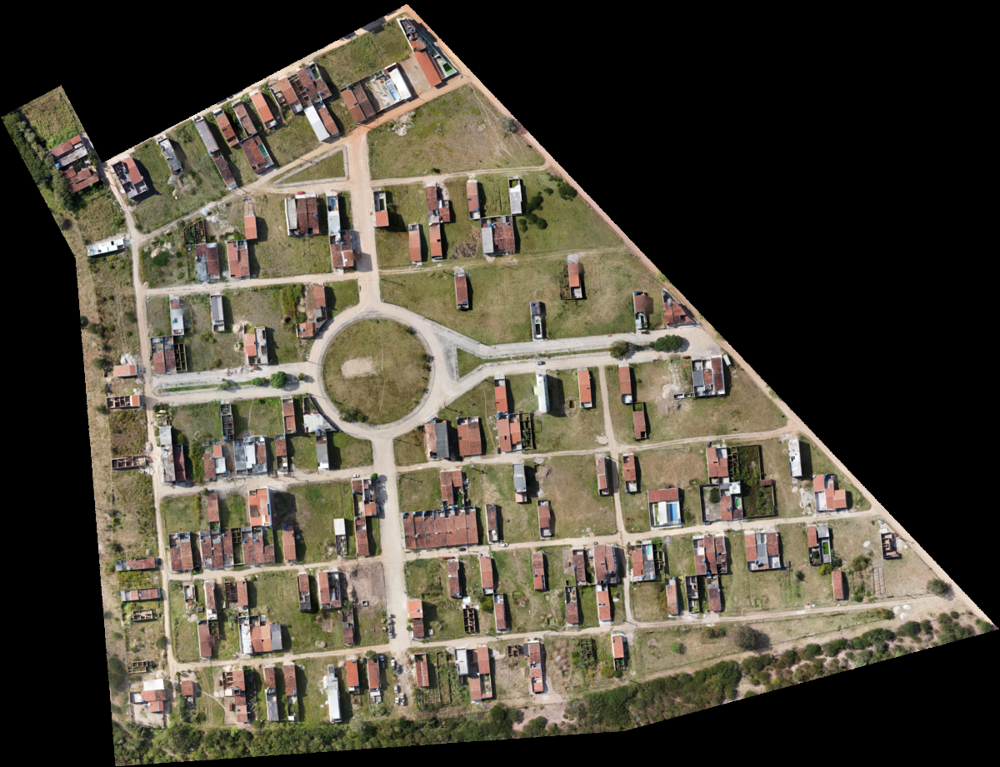

In [13]:
import numpy as np

VIEW_ID = "68a5bc16e5584a0f62bfa08c"   # troque por outro ID da lista para ver outra cena
raster_path = COG_DIR / f"{VIEW_ID}.tif"

# Miniatura leve (no máximo 1200 px no maior lado), reprojetada para WGS84
with rasterio.open(raster_path) as src:
    dst_crs = "EPSG:4326"
    scale = min(1, 1200 / max(src.width, src.height))
    width = max(1, int(src.width * scale))
    height = max(1, int(src.height * scale))

    transform, dst_width, dst_height = calculate_default_transform(
        src.crs, dst_crs, src.width, src.height, *src.bounds, dst_width=width, dst_height=height)

    bands = min(src.count, 3)
    image = np.zeros((bands, dst_height, dst_width), dtype=np.uint8)
    for i in range(bands):
        reproject(
            source=rasterio.band(src, i + 1), destination=image[i],
            src_transform=src.transform, src_crs=src.crs,
            dst_transform=transform, dst_crs=dst_crs, resampling=Resampling.bilinear)
    image = np.moveaxis(image, 0, -1)

    # Limites geográficos da miniatura
    west = transform.c
    north = transform.f
    east = west + transform.a * dst_width
    south = north + transform.e * dst_height

fmap = folium.Map(location=[(south + north) / 2, (west + east) / 2], zoom_start=16, tiles="OpenStreetMap")

folium.raster_layers.ImageOverlay(
    image=image, bounds=[[south, west], [north, east]], opacity=1,
    name=f"Imagem OAM {VIEW_ID[:8]}").add_to(fmap)

footprints = folium.FeatureGroup(name="Pegadas de todas as cenas", show=True)
for _, r in meta.iterrows():
    folium.Rectangle(
        bounds=[[r.south, r.west], [r.north, r.east]],
        color="#0b3d91", weight=1.5, fill=False,
        tooltip=f"{r.item_id[:8]} · {r.gsd_m*100:.1f} cm",
    ).add_to(footprints)
footprints.add_to(fmap)

folium.LayerControl().add_to(fmap)
fmap

## 3. Padronizar a resolução (reamostragem)

As imagens têm resoluções diferentes (de 2,5 cm a 5 cm). Para um modelo de deep learning, isso é um problema. Os modelos de DL com imagens de observação da terra, tendem a aprendem a reconhecer objetos em uma **escala fixa**, e um telhado de 2,5 cm/px não tem o mesmo tamanho em pixels que um telhado de 5 cm/px. Claro que existem soluções para lidar com diferentes resoluções, mas isso é outro papo. Para hoje, vamos padronizar todas as células para **10 cm por pixel**.

Reamostrar é mudar o tamanho do pixel. Para reduzir a resolução, cada novo pixel recebe a **média** dos pixels que ele substitui (`Resampling.average`).

### Compararando visualmente diferentes resoluções

Pegamos uma janela de **512 × 512 pixels** de uma cena com resolução próxima de 4,9 cm (a cena de 2,5 cm foi deixada de fora, por ser um caso muito diferente do restante) e mostramos três versões: a original, a de 5 cm e a de 10 cm.

Repare que a mesma janela de 512 pixels cobre áreas diferentes do chão: quanto maior o pixel, maior a área coberta.

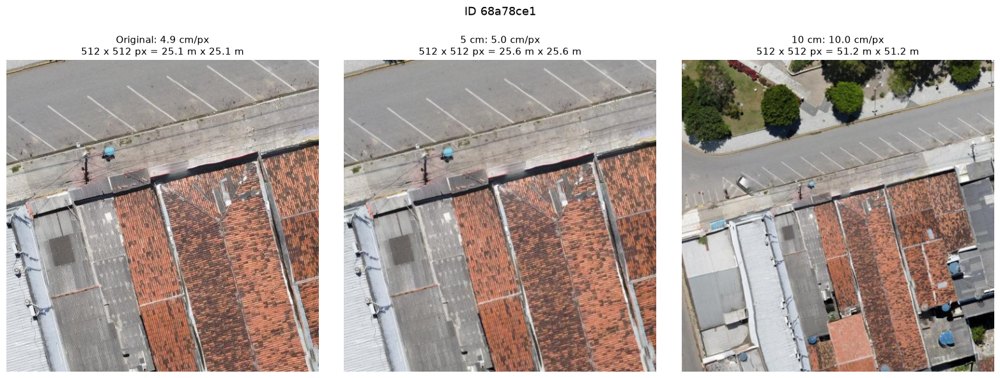

In [20]:
# Cena com resolução mais próxima de 4,9 cm
SCENE_FOR_RES = meta.loc[(meta.gsd_m - 0.049).abs().idxmin(), "item_id"]
native_path = COG_DIR / f"{SCENE_FOR_RES}.tif"

WIN = 512
CASES = [("Original", None), ("5 cm", 0.05), ("10 cm", 0.10)]

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
with rasterio.open(native_path) as src:
    gx, _ = ground_resolution_m(src)
    for ax, (title, gsd) in zip(axes, CASES):
        target = gx if gsd is None else gsd           # metros por pixel desejados
        side = int(round(WIN * target / gx))          # quantos pixels originais cabem na janela
        r0, c0 = (src.height - side) // 2, (src.width - side) // 2
        arr = src.read([1, 2, 3], window=Window(c0+500, r0+500, side, side),
                       out_shape=(3, WIN, WIN), resampling=Resampling.average)
        ax.imshow(np.moveaxis(arr, 0, -1))
        ax.set_title(f"{title}: {target*100:.1f} cm/px\n"
                     f"{WIN} x {WIN} px = {WIN*target:.1f} m x {WIN*target:.1f} m", fontsize=11)
        ax.axis("off")

fig.suptitle(f"ID {SCENE_FOR_RES[:8]}", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

### Reamostrando todas as cenas

Para fazer isso, basta a gente iterar a reamostragem para cada arquivo COG. A fim de diminuir a quantidade de linhas, vamos chamar diretamento o código escrito em: `resampling.py`. Ele usa apenas funções do **rasterio** e salva cada cena como COG. Se a pergunta for porquê utilizar rasterio, bibliotecas maduras são extremamente confiáveis para calcular as funções de espacialidade. 

In [21]:
!{sys.executable} resampling.py --input data/cog --output data/cog_10cm --gsd 0.10

skipped (already exists): data/cog_10cm/685740ade319ef725278cb5a.tif
skipped (already exists): data/cog_10cm/685740b9e319ef725278cb92.tif
skipped (already exists): data/cog_10cm/685740c3e319ef725278cbc1.tif
skipped (already exists): data/cog_10cm/685740c7e319ef725278cbcf.tif
skipped (already exists): data/cog_10cm/68a4a953e50784296730bf0f.tif
skipped (already exists): data/cog_10cm/68a5bc04e5584a0f62bfa047.tif
skipped (already exists): data/cog_10cm/68a5bc16e5584a0f62bfa08c.tif
skipped (already exists): data/cog_10cm/68a5bc31e5584a0f62bfa0ff.tif
skipped (already exists): data/cog_10cm/68a5bc60e5584a0f62bfa185.tif
skipped (already exists): data/cog_10cm/68a5bc63e5584a0f62bfa195.tif
skipped (already exists): data/cog_10cm/68a5bc70e5584a0f62bfa1ce.tif
skipped (already exists): data/cog_10cm/68a78c9e27e991e401df2876.tif
skipped (already exists): data/cog_10cm/68a78caf27e991e401df289b.tif
skipped (already exists): data/cog_10cm/68a78cb427e991e401df28a2.tif
skipped (already exists): data/cog

In [22]:
# Conferência: todas as cenas em 10 cm?
rows = []
for item_id in meta.item_id:
    with rasterio.open(COG10_DIR / f"{item_id}.tif") as s:
        rows.append({"item_id": item_id, "gsd_cm": round(s.res[0] * 100, 2),
                     "largura_px": s.width, "altura_px": s.height, "bandas": s.count})
check10 = pd.DataFrame(rows)
display(check10)
print("Todas com 10 cm?", bool(np.allclose(check10.gsd_cm, 10, atol=0.1)))

,item_id,gsd_cm,largura_px,altura_px,bandas
0,68c41fddae0fc8076633a74e,10.0,1789,5367,3
1,68a78c9e27e991e401df2876,10.0,2399,2760,3
2,68a78caf27e991e401df289b,10.0,5666,3546,3
3,68a5bc60e5584a0f62bfa185,10.0,4528,4977,3
4,68a5bc04e5584a0f62bfa047,10.0,3203,3765,3
5,685740c3e319ef725278cbc1,10.0,2357,3081,3
6,68a78ce127e991e401df2956,10.0,3498,2967,3
7,68a4a953e50784296730bf0f,10.0,3554,2958,3
8,68a78d0527e991e401df29cc,10.0,4138,3319,3
9,68a5bc70e5584a0f62bfa1ce,10.0,5082,3871,3


Todas com 10 cm? True


## 4. Tiling

Aqui cortamos o nosso arquivo em azulejos de mesmo tamanho. 

Uma cena inteira tem milhares de pixels de lado, grande demais para um modelo de deep learning. 
Por isso a cortamos em tiles com um determinado tamanho. Aqui cada tile tem **640 × 640 pixels**, ou seja, 64 m × 64 m no terreno se nossa resolução for de 10cm. 

### Sobreposição e passo (stride)

Os tiles vizinhos se sobrepõem em **40 pixels**. Isso evita que os objetos estejam sempre cortados. Veja que esse valor varia dependendo qual tarefa você está abordando. Esse janela que vai clippando a imagem em sequencia, tem um passo(*stride*)  que determina quanto a janela desloca em cada pixel.

> passo = tamanho − sobreposição = 640 − 40 = **600 px**

Alem disso, tiles com menos de 90% de dados válidos (por exemplo, nas bordas da imagem, onde não há pixels) são descartados.


Para cada tile temos:

- `tiles/`: o azulejo em GeoTIFF, que é o arquivo usado pelo modelo;
- `previews/`: uma miniatura em JPEG, compacta, para o FiftyOne mostrar rapidamente;
- `labels/`: um GeoJSON com os rótulos do azulejo, já recortados para caber nele. Se a cena não tem rótulos, o arquivo existe mesmo assim, mas sem objetos dentro. Assim, todo azulejo tem seu par, e o alinhamento entre imagem e rótulo fica garantido;
- `tiles_index.csv`: uma linha por azulejo, com a posição, o CRS, a cena de origem e se a cena tem rótulos.

### Labels

Vejam que aqui nessa cena estamos já passando alguns rótulos. Como na área não existiam ainda os rótulos corretos, precisamos desenhar na mão.  **labelme** é uma ferramente que te ajuda com essa tarefa. As anotações são exportadas em formato GeoJSON. Cada objeto (o telhado de uma casa por exemplo) guarda um identificador com metadados, vinculando sua informação e rótulo a imagem correta.

In [23]:
TILE = 640                  # tamanho do azulejo, em pixels
OVERLAP = 40                # sobreposição entre azulejos vizinhos, em pixels
STRIDE = TILE - OVERLAP     # passo: quanto a janela avança a cada azulejo
TILES_DIR = ROOT / "data" / "tiles_10cm"

print("Imagens de entrada (10 cm):", COG10_DIR)
print("Rótulos de entrada:        ", LABELS_DIR)
print("Saída dos azulejos:        ", TILES_DIR)
print(f"Azulejo {TILE} px, sobreposição {OVERLAP} px -> passo de {STRIDE} px = {STRIDE * 0.10:.0f} m no terreno")

Imagens de entrada (10 cm): /Users/macuser/Documents/UN/projects/webinar-DL/data/cog_10cm
Rótulos de entrada:         /Users/macuser/Documents/UN/projects/webinar-DL/data/cog_10cm/geojson_labelling
Saída dos azulejos:         /Users/macuser/Documents/UN/projects/webinar-DL/data/tiles_10cm
Azulejo 640 px, sobreposição 40 px -> passo de 600 px = 60 m no terreno


In [25]:
index_path = tile_cogs(COG10_DIR, TILES_DIR, gsd=None, tile=TILE, overlap=OVERLAP,
                       labels_dir=LABELS_DIR, previews=True)

index = index_with_paths(TILES_DIR)
print(f"{len(index)} azulejos no total; {int(index.labelled.sum())} desses tiles contém anotações")
print(f"Índice salvo em: {index_path}")

labels: 737 features from /Users/macuser/Documents/UN/projects/webinar-DL/data/cog_10cm/geojson_labelling for 3 scenes
685740ade319ef725278cb5a.tif: 11 tiles
685740b9e319ef725278cb92.tif: 42 tiles
685740c3e319ef725278cbc1.tif: 7 tiles
685740c7e319ef725278cbcf.tif: 19 tiles
68a4a953e50784296730bf0f.tif: 13 tiles
68a5bc04e5584a0f62bfa047.tif: 10 tiles
68a5bc16e5584a0f62bfa08c.tif: 37 tiles
68a5bc31e5584a0f62bfa0ff.tif: 8 tiles
68a5bc60e5584a0f62bfa185.tif: 24 tiles
68a5bc63e5584a0f62bfa195.tif: 13 tiles
68a5bc70e5584a0f62bfa1ce.tif: 19 tiles
68a78c9e27e991e401df2876.tif: 7 tiles
68a78caf27e991e401df289b.tif: 29 tiles
68a78cb427e991e401df28a2.tif: 16 tiles
68a78ce127e991e401df2956.tif: 10 tiles
68a78d0527e991e401df29cc.tif: 9 tiles
68c41fddae0fc8076633a74e.tif: 12 tiles
286 tiles from 17 scenes -> /Users/macuser/Documents/UN/projects/webinar-DL/data/tiles_10cm/ (index: tiles_index.csv)
286 azulejos no total; 31 desses tiles contém anotações
Índice salvo em: /Users/macuser/Documents/UN/pro

### Mosaico dos azulejos

Para ver como o corte ficou, montamos um mosaico com **50 azulejos escolhidos ao acaso**. O gráfico é interativo: passe o mouse sobre um azulejo para ver seu ID, a cena de origem e se ele tem rótulos.

In [30]:
fig.layout

Layout({
    'height': 800,
    'margin': {'b': 10, 'l': 10, 'r': 10, 't': 60},
    'showlegend': False,
    'template': '...',
    'title': {'text': 'Tiles gerados a partir de todas as imagens de drone.'},
    'xaxis': {'anchor': 'y', 'domain': [0.0, 1.0], 'visible': False},
    'yaxis': {'anchor': 'x', 'domain': [0.0, 1.0], 'visible': False}
})

In [31]:
N_SHOW, COLS, THUMB = 50, 10, 160

sample_tiles = index.sample(n=min(N_SHOW, len(index)), random_state=42).reset_index(drop=True)
rows_n = int(np.ceil(len(sample_tiles) / COLS))
mosaic = np.full((rows_n * THUMB, COLS * THUMB, 3), 255, dtype=np.uint8)

xs, ys, hover = [], [], []
for k, t in enumerate(sample_tiles.itertuples(index=False)):
    r, c = divmod(k, COLS)
    thumb = Image.open(TILES_DIR / "previews" / f"{t.tile_id}.jpg").convert("RGB").resize((THUMB, THUMB))
    mosaic[r * THUMB:(r + 1) * THUMB, c * THUMB:(c + 1) * THUMB] = np.asarray(thumb)
    xs.append(c * THUMB + THUMB / 2)
    ys.append(r * THUMB + THUMB / 2)
    hover.append(f"{t.tile_id}<br>cena {t.scene_id[:8]}<br>com rótulos: {'sim' if t.labelled else 'não'}")

fig = px.imshow(mosaic)
fig.update_traces(hoverinfo="skip", selector=dict(type="image"))
fig.add_trace(go.Scatter(x=xs, y=ys, mode="markers", text=hover,
                         marker=dict(size=40, opacity=0), hovertemplate="%{text}<extra></extra>"))
fig.update_layout(title=f"Tiles gerados a partir das imagens de drone.",
                  height=800, showlegend=False, margin=dict(l=10, r=10, t=60, b=10))
fig.update_xaxes(visible=False)
fig.update_yaxes(visible=False)
fig.show()

## 5. Gerenciamento do Dataset

Agora que já preparamos as imagens para tornar-se um dataset, podemos explorar softwares gratuitos que nos permitem gerenciá-los. 


O **[FiftyOne](https://docs.voxel51.com/)** é uma dessas ferramenta *open-source* para explorar datasets de visão computacional. Cada **imagem** (*sample*) possui um ID único e recebe a classe `fiftyone.Sample`. Essa classe pode possuir múltiplos campos como as anotações, metadados de altura, largura, tamanho. Anotações feitas por modelos como o YOLO, etc. Os objetos possuem um caixa delimitadora, por ai vai. 

Fiftyone possui uma linguagem parecidade com o Pandas, e portanto permite facilmente manipular as imagens, extrair informações e principalmente, analisar a performance de modelos. 


------

Então vamos criar esse dataset diretamente no fiftyone. 

In [32]:
DATASET_NAME = "webinar-tiles-10cm"

# Um dicionário por TILE: caixas em pixels do TILE e classes, lidas dos GeoJSON
samples = read_tile_samples(TILES_DIR, tile=TILE)
annotations = {s["tile_id"]: s for s in samples}

if DATASET_NAME in fo.list_datasets():
    fo.delete_dataset(DATASET_NAME)
dataset = fo.Dataset(DATASET_NAME, persistent=True)

new_samples = []
for t in index.itertuples(index=False):
    sample = fo.Sample(
        filepath=str(TILES_DIR / "previews" / f"{t.tile_id}.jpg"),   # miniatura mostrada no App
        tif_path=str(TILES_DIR / "tiles" / f"{t.tile_id}.tif"),       # azulejo original (usado nos embeddings)
        tile_id=t.tile_id,
        scene_id=t.scene_id,
        gsd_m=float(t.gsd_m),
        valid_fraction=float(t.valid_fraction),
        location=fo.GeoLocation(point=[float(t.centre_lon), float(t.centre_lat)]),
        annotated=bool(t.labelled),
    )
    ann = annotations.get(t.tile_id)
    if t.labelled and ann is not None:
        sample["anotacoes"] = fo.Detections(detections=[
            fo.Detection(label=cls, bounding_box=[x1 / TILE, y1 / TILE, (x2 - x1) / TILE, (y2 - y1) / TILE])
            for (x1, y1, x2, y2), cls in zip(ann["boxes"], ann["class_names"])
        ])
    new_samples.append(sample)
dataset.add_samples(new_samples)

print(dataset)
print("azulejos anotados:", dataset.count_values("annotated").get(True, 0))

 100% |█████████████████| 286/286 [145.7ms elapsed, 0s remaining, 2.0K samples/s]  
Name:        webinar-tiles-10cm
Media type:  image
Num samples: 286
Persistent:  True
Tags:        []
Sample fields:
    id:               fiftyone.core.fields.ObjectIdField
    filepath:         fiftyone.core.fields.StringField
    tags:             fiftyone.core.fields.ListField(fiftyone.core.fields.StringField)
    metadata:         fiftyone.core.fields.EmbeddedDocumentField(fiftyone.core.metadata.ImageMetadata)
    created_at:       fiftyone.core.fields.DateTimeField
    last_modified_at: fiftyone.core.fields.DateTimeField
    tif_path:         fiftyone.core.fields.StringField
    tile_id:          fiftyone.core.fields.StringField
    scene_id:         fiftyone.core.fields.StringField
    gsd_m:            fiftyone.core.fields.FloatField
    valid_fraction:   fiftyone.core.fields.FloatField
    location:         fiftyone.core.fields.EmbeddedDocumentField(fiftyone.core.labels.GeoLocation)
    annotat

In [38]:
dataset.first()

<Sample: {
    'id': '6af5f7ddbf34a93f2ff75917',
    'media_type': 'image',
    'filepath': '/Users/macuser/Documents/UN/projects/webinar-DL/data/tiles_10cm/previews/685740ade319ef725278cb5a_r01_c01.jpg',
    'tags': [],
    'metadata': None,
    'created_at': datetime.datetime(2026, 11, 12, 17, 31, 9, 887670),
    'last_modified_at': datetime.datetime(2026, 11, 12, 17, 31, 9, 887670),
    'tif_path': '/Users/macuser/Documents/UN/projects/webinar-DL/data/tiles_10cm/tiles/685740ade319ef725278cb5a_r01_c01.tif',
    'tile_id': '685740ade319ef725278cb5a_r01_c01',
    'scene_id': '685740ade319ef725278cb5a',
    'gsd_m': 0.1,
    'valid_fraction': 1.0,
    'location': <GeoLocation: {
        'id': '6af5f7ddbf34a93f2ff754dc',
        'tags': [],
        'point': [-36.446006, -8.523558],
        'line': None,
        'polygon': None,
    }>,
    'annotated': True,
    'anotacoes': <Detections: {
        'detections': [
            <Detection: {
                'id': '6af5f7ddbf34a93f2ff754dd',

In [39]:
import fiftyone as fo

session = fo.launch_app(dataset, auto=False)

Session launched. Run `session.show()` to open the App in a cell output.


In [44]:
session.view = view_anotacoes


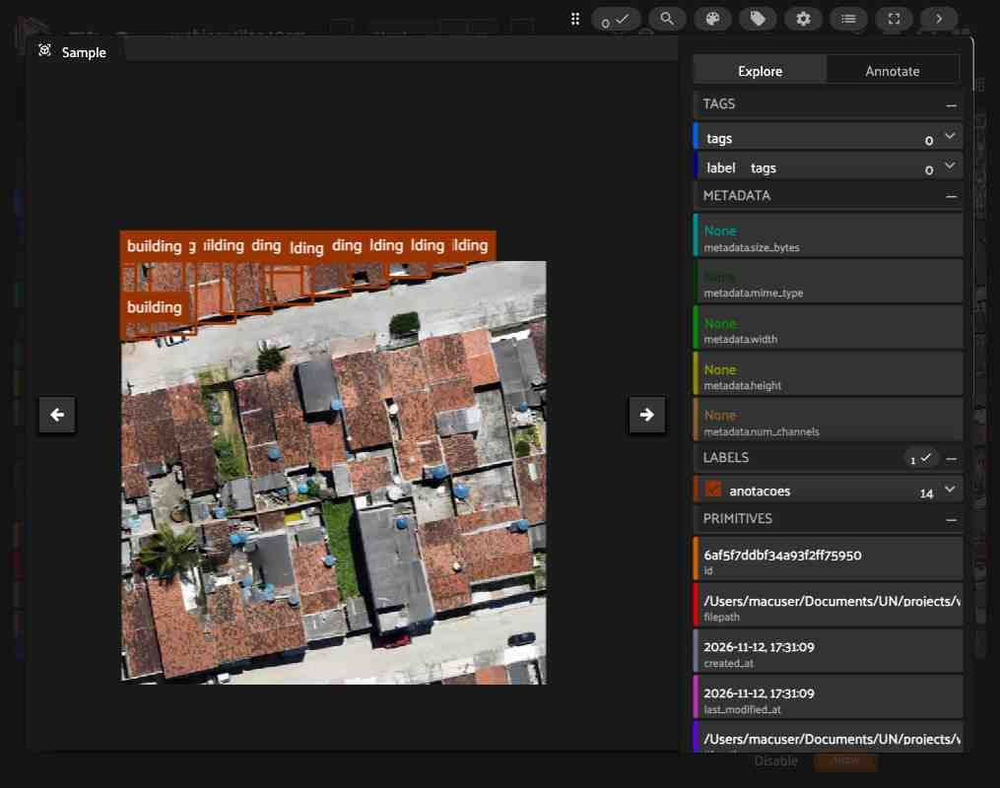

In [40]:
session.show()

In [41]:
#vamos filtrar nosso dataset dinamicamente

# filtrar apenas para uma imagem ID
ITEM_IDS

['68c41fddae0fc8076633a74e',
 '68a78c9e27e991e401df2876',
 '68a78cb427e991e401df28a2',
 '68a78ce127e991e401df2956',
 '68a78caf27e991e401df289b',
 '68a78d0527e991e401df29cc',
 '685740b9e319ef725278cb92',
 '685740c7e319ef725278cbcf',
 '685740ade319ef725278cb5a',
 '685740c3e319ef725278cbc1',
 '68a4a953e50784296730bf0f',
 '68a5bc60e5584a0f62bfa185',
 '68a5bc63e5584a0f62bfa195',
 '68a5bc16e5584a0f62bfa08c',
 '68a5bc04e5584a0f62bfa047',
 '68a5bc70e5584a0f62bfa1ce',
 '68a5bc31e5584a0f62bfa0ff']

In [55]:
dataset.match(
    F("scene_id")=="68a5bc31e5584a0f62bfa0ff"
)

Dataset:     webinar-tiles-10cm
Media type:  image
Num samples: 8
Sample fields:
    id:               fiftyone.core.fields.ObjectIdField
    filepath:         fiftyone.core.fields.StringField
    tags:             fiftyone.core.fields.ListField(fiftyone.core.fields.StringField)
    metadata:         fiftyone.core.fields.EmbeddedDocumentField(fiftyone.core.metadata.ImageMetadata)
    created_at:       fiftyone.core.fields.DateTimeField
    last_modified_at: fiftyone.core.fields.DateTimeField
    tif_path:         fiftyone.core.fields.StringField
    tile_id:          fiftyone.core.fields.StringField
    scene_id:         fiftyone.core.fields.StringField
    gsd_m:            fiftyone.core.fields.FloatField
    valid_fraction:   fiftyone.core.fields.FloatField
    location:         fiftyone.core.fields.EmbeddedDocumentField(fiftyone.core.labels.GeoLocation)
    annotated:        fiftyone.core.fields.BooleanField
    anotacoes:        fiftyone.core.fields.EmbeddedDocumentField(fiftyone.c

In [54]:
dataset.first()

<Sample: {
    'id': '6af5f7ddbf34a93f2ff75917',
    'media_type': 'image',
    'filepath': '/Users/macuser/Documents/UN/projects/webinar-DL/data/tiles_10cm/previews/685740ade319ef725278cb5a_r01_c01.jpg',
    'tags': [],
    'metadata': None,
    'created_at': datetime.datetime(2026, 11, 12, 17, 31, 9, 887000),
    'last_modified_at': datetime.datetime(2026, 11, 12, 17, 31, 9, 887000),
    'tif_path': '/Users/macuser/Documents/UN/projects/webinar-DL/data/tiles_10cm/tiles/685740ade319ef725278cb5a_r01_c01.tif',
    'tile_id': '685740ade319ef725278cb5a_r01_c01',
    'scene_id': '685740ade319ef725278cb5a',
    'gsd_m': 0.1,
    'valid_fraction': 1.0,
    'location': <GeoLocation: {
        'id': '6af5f7ddbf34a93f2ff754dc',
        'tags': [],
        'point': [-36.446006, -8.523558],
        'line': None,
        'polygon': None,
    }>,
    'annotated': True,
    'anotacoes': <Detections: {
        'detections': [
            <Detection: {
                'id': '6af5f7ddbf34a93f2ff754dd',

In [43]:
from fiftyone import ViewField as F
view_anotacoes = dataset.match(
    F("anotacoes.detections").exists()
)
view_anotacoes

Dataset:     webinar-tiles-10cm
Media type:  image
Num samples: 31
Sample fields:
    id:               fiftyone.core.fields.ObjectIdField
    filepath:         fiftyone.core.fields.StringField
    tags:             fiftyone.core.fields.ListField(fiftyone.core.fields.StringField)
    metadata:         fiftyone.core.fields.EmbeddedDocumentField(fiftyone.core.metadata.ImageMetadata)
    created_at:       fiftyone.core.fields.DateTimeField
    last_modified_at: fiftyone.core.fields.DateTimeField
    tif_path:         fiftyone.core.fields.StringField
    tile_id:          fiftyone.core.fields.StringField
    scene_id:         fiftyone.core.fields.StringField
    gsd_m:            fiftyone.core.fields.FloatField
    valid_fraction:   fiftyone.core.fields.FloatField
    location:         fiftyone.core.fields.EmbeddedDocumentField(fiftyone.core.labels.GeoLocation)
    annotated:        fiftyone.core.fields.BooleanField
    anotacoes:        fiftyone.core.fields.EmbeddedDocumentField(fiftyone.

finalmente...

# Embeddings!

Vamos extrair  **embeddings** da imagens. Cada embedding tem um comportamento associado ao o modelo que o treinou. Então as diferentes características do modelo como arquitetura, dados utilizados, hiperparamêtros do modelo, etc , transformam o embedding. Contudo, quando se utilizam os embeddings advindo dos mesmo modelo, podemos fazer comparações e extrair insights dos datasets, até mesmo entender como os modelos estão performando e onde falham. 

Como modelo para extrair os embeddings, vamos utilizar o  **DINOv2**. Apesar do Dinov3 ser um melhor modelo, mencionado na aula, o Dinov2 não necessita de chave API para baixar seus pesos. Dito isso, quando retiramos os modelos do [HuggingFace](https://huggingface.co/), significa que você pode baixar qualquer modelo daqui, e utilizar para milhares de coisas diferentes. 

A maioria desses modelos, permite que você acesse eles através da bibioteca [Transformers](https://huggingface.co/docs/transformers/en/index)

### O que é a biblioteca `transformers`?

A `transformers`, do Hugging Face, dá acesso a milhares de modelos pré-treinados (visão, texto, áudio) com a mesma interface. Pense como blocos de lego, e essas seriam algumas de suas peças:

- **Arquitetura e pesos:** a arquitetura é o desenho da rede neural. Os pesos são os números aprendidos no treinamento. O nome `facebook/dinov2-small` identifica os dois juntos. [Olhe aqui](https://huggingface.co/facebook/dinov2-small)
- **`AutoModel`:** lê o nome do modelo, descobre a arquitetura sozinho e baixa os pesos do Hub. O "Auto" quer dizer que não precisamos saber a classe exata.
- **`AutoImageProcessor`:** prepara a imagem do jeito que o modelo espera. Aqui ele poderia redimensionar, escalar, converter tensor e qualquer outra etapa de pre-processamento. Se pularmos esta etapa, o modelo recebe números fora da escala de treinamento e erra.



In [56]:
MODEL_ID = "facebook/dinov2-small"
PATCH = 14
INPUT_PX = 644            # 46 x 46 patches; o múltiplo de 14 mais próximo de 640
BATCH_SIZE = 32
FORCE_RECOMPUTE = False   # True para refazer os embeddings mesmo que o arquivo exista

EMB_DIR = ROOT / "data" / "embeddings"
EMB_DIR.mkdir(parents=True, exist_ok=True)
EMB_FILE = EMB_DIR / "tiles10cm_dinov2s.npz"

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print("dispositivo:", DEVICE, "| torch", torch.__version__, "| fiftyone", fo.__version__)
print("arquivo de embeddings:", EMB_FILE.relative_to(ROOT))

dispositivo: mps | torch 2.15.0 | fiftyone 1.22.1
arquivo de embeddings: data/embeddings/tiles10cm_dinov2s.npz


In [57]:
t0 = time.time()
processor = AutoImageProcessor.from_pretrained(
    MODEL_ID,
    size={"height": INPUT_PX, "width": INPUT_PX},
    do_center_crop=False,
)
model = AutoModel.from_pretrained(MODEL_ID).to(DEVICE).eval()
print(f"{MODEL_ID} carregado em {time.time() - t0:.1f} s")
print("dimensão do embedding (hidden size):", model.config.hidden_size,
      "| patches por azulejo:", (INPUT_PX // PATCH) ** 2)

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

facebook/dinov2-small carregado em 0.8 s
dimensão do embedding (hidden size): 384 | patches por azulejo: 2116


### Feito! Modelo carregado e pronto para testar 

#### Testando em um único tile

Antes de processar todos, testamos o caminho completo com um único azulejo: ler o GeoTIFF, preparar a imagem, passar pelo modelo e conferir o formato da saída.

In [58]:
first = dataset.first()
with rasterio.open(first.tif_path) as src:
    arr = src.read([1, 2, 3])
pix = processor(images=Image.fromarray(np.moveaxis(arr, 0, -1)), return_tensors="pt")["pixel_values"]
with torch.inference_mode():
    tokens = model(pixel_values=pix.to(DEVICE)).last_hidden_state
print("pixel_values:", tuple(pix.shape), "| tokens:", tuple(tokens.shape), "(1 CLS + patches)")
assert tokens.shape[1] == 1 + (INPUT_PX // PATCH) ** 2

pixel_values: (1, 3, 644, 644) | tokens: (1, 2117, 384) (1 CLS + patches)


In [60]:
tokens.shape

torch.Size([1, 2117, 384])

In [68]:
tokens[:, 0, :].shape

torch.Size([1, 384])

## Curioso? 

Entenda mais sobre a arquitetura do Dinov2 aqui: [DinoV2](https://storrs.io/dinov2-explained/?utm_source=chatgpt.com)

### Extraindo os embeddings de todo o dataset

Agora que entendemos de embeddings, vamos extraí-los de nosso modelo e ganhar insights de nosso dataset.


In [64]:
class TileDataset(Dataset):
    # Lê cada azulejo (GeoTIFF) e devolve uma imagem RGB
    def __init__(self, paths):
        self.paths = list(paths)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        with rasterio.open(self.paths[i]) as src:
            arr = src.read([1, 2, 3])
        return Image.fromarray(np.moveaxis(arr, 0, -1))

def collate(images):
    return processor(images=images, return_tensors="pt")["pixel_values"]

def extract(paths):
    loader = DataLoader(TileDataset(paths), batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=0, collate_fn=collate)
    out = np.empty((len(paths), model.config.hidden_size), dtype=np.float32)
    row, t0 = 0, time.time()
    for pixels in loader:
        with torch.inference_mode():
            cls = model(pixel_values=pixels.to(DEVICE)).last_hidden_state[:, 0, :].float()
        cls = torch.nn.functional.normalize(cls, dim=1)
        out[row:row + len(cls)] = cls.cpu().numpy()
        row += len(cls)
        print(f"  {row}/{len(paths)} azulejos, {time.time() - t0:.0f} s")
    assert row == len(paths)
    return out

if EMB_FILE.exists() and not FORCE_RECOMPUTE:
    print(f"{EMB_FILE.relative_to(ROOT)} já existe: pulando a extração.")
else:
    sample_ids = dataset.values("id")
    tif_paths = dataset.values("tif_path")
    t0 = time.time()
    embeddings = extract(tif_paths)
    print(f"pronto: {embeddings.shape} em {(time.time() - t0) / 60:.1f} min")
    np.savez_compressed(
        EMB_FILE,
        embeddings=embeddings,
        sample_ids=np.array(sample_ids),
        tile_ids=np.array(dataset.values("tile_id")),
        model_id=np.array(MODEL_ID),
        input_size=np.array(INPUT_PX),
    )
    print(f"salvo em {EMB_FILE.relative_to(ROOT)} ({EMB_FILE.stat().st_size / 1e6:.1f} MB)")

  32/286 azulejos, 4 s
  64/286 azulejos, 8 s
  96/286 azulejos, 11 s
  128/286 azulejos, 15 s
  160/286 azulejos, 19 s
  192/286 azulejos, 22 s
  224/286 azulejos, 26 s
  256/286 azulejos, 30 s
  286/286 azulejos, 33 s
pronto: (286, 384) em 0.6 min
salvo em data/embeddings/tiles10cm_dinov2s.npz (0.4 MB)


In [66]:
embeddings.shape

(286, 384)

### Carregar os embeddings dentro do dataset

Os embeddings ficam no arquivo `.npz`, e não no FiftyOne. Cada linha da matriz precisa corresponder ao azulejo certo. Alinhamos pelo `tile_id` (o nome do azulejo), que não muda quando o dataset é recriado, e não pelo ID interno do FiftyOne, que muda a cada nova criação.

In [71]:
data = np.load(EMB_FILE)
emb_raw = data["embeddings"]
print("embeddings:", emb_raw.shape, "| modelo:", str(data["model_id"]), "| entrada:", int(data["input_size"]), "px")
print("Normalizado?", bool(np.allclose(np.linalg.norm(emb_raw, axis=1), 1.0, atol=1e-4)))

row_of = {tid: i for i, tid in enumerate(data["tile_ids"])}
tile_ids = dataset.values("tile_id")
missing = [t for t in tile_ids if t not in row_of]
assert not missing, f"{len(missing)} azulejos do dataset não têm embedding: rode de novo com FORCE_RECOMPUTE = True"
emb = emb_raw[[row_of[t] for t in tile_ids]]     # mesma ordem das amostras do dataset
ids = dataset.values("id")                       # IDs internos do FiftyOne, usados nas funções de análise
print("Imagens", len(ids), "Shape Embeddings:", emb.shape)

embeddings: (286, 384) | modelo: facebook/dinov2-small | entrada: 644 px
Normalizado? True
Imagens 286 Shape Embeddings: (286, 384)


# Como são esses embeddings?

Um **embedding** é uma lista de números, ou seja, um **vetor**, que representa o conteúdo de uma imagem. Cada imagem vira um ponto em um espaço com 384 dimensões (cada dimensão é um número do vetor). Não há um significado fixo para cada dimensão, é o resultado do aprendizado do modelo, então é a forma como o modelo organiza a informação. 


Pode-se entender os embeddings como uma representação em um espaço latente, da imagem. O modelo aprendeu a organizar a informação em uma espaço hiperdimensional. Dessa forma, isso cria algumas propriedades do embeddings, como o fato de formas e imagens parecidas terem um maior proximidade no espaço. 

Para analisar esse espaço, vamos analisar através de uma distância cosseno entre os vetores.

In [78]:
print("Formato da matriz:", emb.shape, " (numero de tiles (imagens), dimensões)")
print("Tipo de dado:", emb.dtype, "| memória:", f"{emb.nbytes / 1e6:.2f} MB")

v = emb[0]
print("\nPrimeiro azulejo, primeiros 10 números do vetor:")
print(np.round(v[:10], 4))
print("\nNorma (comprimento) do vetor:", round(float(np.linalg.norm(v)), 4), "(1.0 = normalizado)")
print("Menor e maior valor de todo o conjunto:", round(float(emb.min()), 3), round(float(emb.max()), 3))
print("Média das 5 primeiras dimensões (no conjunto todo):", np.round(emb.mean(axis=0)[:5], 4))


print('-----------')
print("\nSe o vetor tem norma 1, a similaridade de cosseno vira um produto escalar.")



Formato da matriz: (286, 384)  (numero de tiles (imagens), dimensões)
Tipo de dado: float32 | memória: 0.44 MB

Primeiro azulejo, primeiros 10 números do vetor:
[-0.0667  0.0207  0.0874 -0.0048  0.0295  0.0147 -0.0698 -0.002  -0.0121
  0.0309]

Norma (comprimento) do vetor: 1.0 (1.0 = normalizado)
Menor e maior valor de todo o conjunto: -0.203 0.197
Média das 5 primeiras dimensões (no conjunto todo): [-0.0634  0.0159  0.0864 -0.0235  0.0261]
-----------

Se o vetor tem norma 1, a similaridade de cosseno vira um produto escalar.


### Como visualizar os embeddings? 

É impossível visualizar um embedding em 384 dimensões, portanto temos que reduzir essas dimensões para um espaço 2D ou 3D, a fim de conseguirmos visualizar algo.  A **redução de dimensionalidade** é a técnica de Machine-Learning que projeta os pontos em 2 dimensões tentando manter a estrutura, ou seja, quem é vizinho de quem.
Existem diversas técnicas, entre elas:

- **PCA** (*Principal Component Analysis*): encontra as direções de maior variação nos dados (os componentes principais) e descarta as menos informativas. É uma transformação linear e rápida. Aqui a usamos primeiro, para reduzir de 384 para 50 dimensões.
- **t-SNE** (*t-distributed Stochastic Neighbor Embedding*): é não linear e foca em preservar a **vizinhança local**: pontos que estão perto no espaço original ficam perto no desenho. É excelente para visualização, mas tem cuidados: as distâncias entre grupos distantes não são confiáveis, o parâmetro **perplexidade** (aqui 30) controla quantos vizinhos cada ponto considera, e o resultado depende da semente aleatória.

O t-SNE é calculado apenas uma vez, o que fazemos a seguir é como interpretar os embeddings dando a eles características de suas classes, como por exemplo, coloring por ID do Azulejo, por tipo de anotação, etc.

In [84]:
n_pca = min(50, emb.shape[0] - 1, emb.shape[1])
pca = PCA(n_components=n_pca, random_state=42)
reduced = pca.fit_transform(emb)
print(f"PCA: {emb.shape[1]} - {n_pca} dimensões, mantendo {pca.explained_variance_ratio_.sum():.1%} da variância")

points = TSNE(n_components=2, perplexity=21, init="pca", learning_rate="auto", random_state=42).fit_transform(reduced)
print("t-SNE pronto:", points.shape)

PCA: 384 - 50 dimensões, mantendo 87.4% da variância
t-SNE pronto: (286, 2)


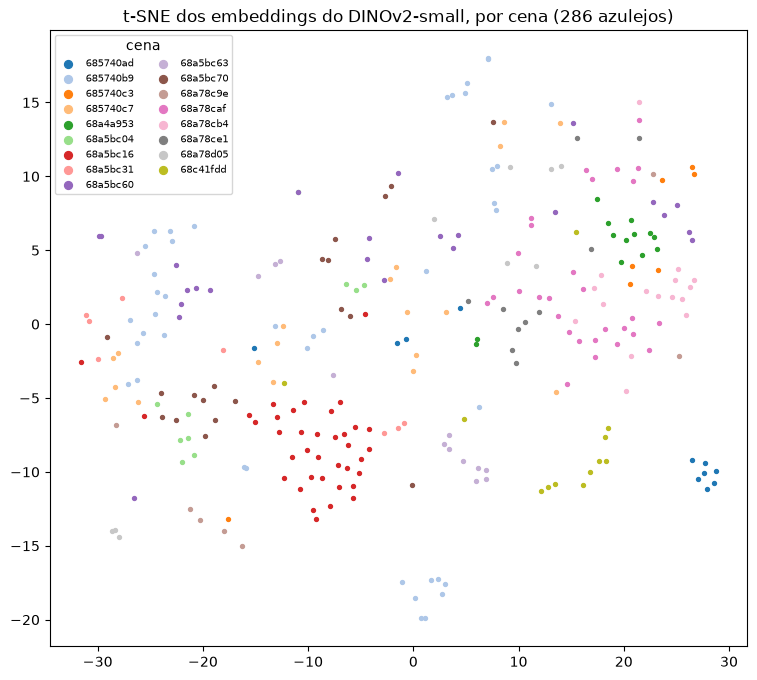

In [85]:
# Gráfico estático (aparece também no notebook), colorido pela cena de origem
scene_ids = np.array(dataset.values("scene_id"))
fig, ax = plt.subplots(figsize=(9, 8))
cmap = plt.get_cmap("tab20")
for k, sc in enumerate(sorted(set(scene_ids))):
    m = scene_ids == sc
    ax.scatter(points[m, 0], points[m, 1], s=8, color=cmap(k % 20), label=sc[:8])
ax.set_title(f"t-SNE dos embeddings do DINOv2-small, por cena ({len(ids)} azulejos)")
ax.legend(markerscale=2, fontsize=7, ncol=2, title="cena")
plt.show()

### Explorando visualmente os embeddings

O gráfico abaixo é interativo e ligado ao App do FiftyOne. Use a seleção com laço (*lasso*) para escolher um grupo de pontos: as miniaturas no App são filtradas para os azulejos escolhidos.

Perguntas para explorar: azulejos da mesma cena ficam juntos? Existem grupos de azulejos parecidos vindo de cenas diferentes?

In [ ]:
# check if session exists
session.

In [ ]:
session.close

In [ ]:
session = fo.launch_app(dataset, auto=False)
plot_scene = fo.scatterplot(
    points,
    samples=dataset,
    ids=ids,                              # o ponto i pertence à amostra ids[i]
    labels=list(scene_ids),
    title="t-SNE (DINOv2-small) · cor = cena",
)

Session launched. Run `session.show()` to open the App in a cell output.


The `show_confidence` App config option has been removed and no longer has any effect. Label attribute visibility is controlled per attribute in the App's sidebar
The `show_index` App config option has been removed and no longer has any effect. Label attribute visibility is controlled per attribute in the App's sidebar
The `show_label` App config option has been removed and no longer has any effect. Label attribute visibility is controlled per attribute in the App's sidebar
The `show_confidence` App config option has been removed and no longer has any effect. Label attribute visibility is controlled per attribute in the App's sidebar
The `show_index` App config option has been removed and no longer has any effect. Label attribute visibility is controlled per attribute in the App's sidebar
The `show_label` App config option has been removed and no longer has any effect. Label attribute visibility is controlled per attribute in the App's sidebar


In [89]:
plot_scene

FigureWidget({
    'data': [{'customdata': array(['6af5f7ddbf34a93f2ff75917', '6af5f7ddbf34a93f2ff75918',
                                   '6af5f7ddbf34a93f2ff75919', '6af5f7ddbf34a93f2ff7591a',
                                   '6af5f7ddbf34a93f2ff7591b', '6af5f7ddbf34a93f2ff7591c',
                                   '6af5f7ddbf34a93f2ff7591d', '6af5f7ddbf34a93f2ff7591e',
                                   '6af5f7ddbf34a93f2ff7591f', '6af5f7ddbf34a93f2ff75920',
                                   '6af5f7ddbf34a93f2ff75921'], dtype=object),
              'hovertemplate': ('<b>label: %{text}</b><br>x, y ' ... ': %{customdata}<extra></extra>'),
              'line': {'color': '#AA0DFE'},
              'mode': 'markers',
              'name': np.str_('685740ade319ef725278cb5a'),
              'showlegend': True,
              'text': array(['685740ade319ef725278cb5a', '685740ade319ef725278cb5a',
                             '685740ade319ef725278cb5a', '685740ade319ef725278cb5a',
       

In [90]:
session.plots.attach(plot_scene, name="tsne_cenas") 

In [93]:
session

Dataset:          webinar-tiles-10cm
Media type:       image
Num samples:      286
Selected samples: 0
Selected labels:  0
Session URL:      http://localhost:5151/
Connected plots:
    tsne_cenas: fiftyone.core.plots.plotly.InteractiveScatter

In [ ]:
# Se quiser fazer local, so importar o npz aqiu
#EMB_FILE=np.load("your-path-to-the-npz")
# data_check = np.load(EMB_FILE)
# emb, npz_ids = data_check["embeddings"], data_check["sample_ids"]
# print("embeddings:", emb.shape, "| model:", str(data["model_id"]), "| input:", int(data["input_size"]))
# print("unit length:", bool(np.allclose(np.linalg.norm(emb, axis=1), 1.0, atol=1e-4)))

# row_of = {sid: i for i, sid in enumerate(npz_ids)}
# dataset_ids = dataset.values("id")
# missing = [s for s in dataset_ids if s not in row_of]
# assert not missing, f"{len(missing)} dataset samples have no embedding"
# aligned = emb[[row_of[s] for s in dataset_ids]]

embeddings: (286, 384) | model: facebook/dinov2-small | input: 644
unit length: True


In [ ]:
# caso o de cima não funcione 
# import fiftyone as fo
# import fiftyone.brain as fob
# import fiftyone.zoo as foz

# fob.compute_visualization(
#     dataset,
#     method="tsne",
#     brain_key="tsne_viz",
#     embeddings=aligned,
#     num_dims=2,
#     perplexity=67,
#     seed=67,
#     verbose=True,
#     pca_dims=67,
# )

Generating visualization...
[t-SNE] Computing 202 nearest neighbors...
[t-SNE] Indexed 286 samples in 0.001s...
[t-SNE] Computed neighbors for 286 samples in 0.013s...
[t-SNE] Computed conditional probabilities for sample 286 / 286
[t-SNE] Mean sigma: 0.266553
[t-SNE] Computed conditional probabilities in 0.008s
[t-SNE] Iteration 50: error = 57.2533493, gradient norm = 0.2828037 (50 iterations in 0.030s)
[t-SNE] Iteration 100: error = 57.5016327, gradient norm = 0.2889252 (50 iterations in 0.027s)
[t-SNE] Iteration 150: error = 57.2194328, gradient norm = 0.2858421 (50 iterations in 0.022s)
[t-SNE] Iteration 200: error = 56.5938339, gradient norm = 0.2575064 (50 iterations in 0.022s)
[t-SNE] Iteration 250: error = 57.2167740, gradient norm = 0.2492374 (50 iterations in 0.021s)
[t-SNE] KL divergence after 250 iterations with early exaggeration: 57.216774
[t-SNE] Iteration 300: error = 0.6337163, gradient norm = 0.0073736 (50 iterations in 0.020s)
[t-SNE] Iteration 350: error = 0.4180930

## Como explorar esses embeddings no espaço latente

A ideia é que podemos utilizar conceitos de machine learning para agrupar, separar e medir distância entre os embeddings. Por exemplo, os métodos de cluster que existem, podemos aplica-los aos embeddings.

Porém, lembramos que para comparar os embeddings, seja em distância, utilizaremos a distância de cosseno.
A métrica é utilizar essa similaridade de cosseno entre dois ou mais vetores. 

Nesse caso, a similaridade de cosseno mede o **ângulo** entre dois vetores, e não o tamanho deles:

- **1**: mesma direção (muito parecidos);
- **0**: perpendiculares (sem relação);
- **−1**: direções opostas.

Como nossos vetores têm norma 1, a similaridade de cosseno é simplesmente o **produto escalar** entre eles. Vamos ver isso na prática: escolhemos uma **âncora** e cinco azulejos ao acaso, e comparamos cada um com a âncora.

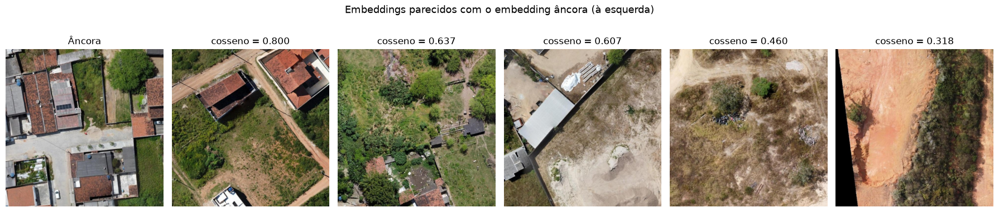

In [98]:
random.seed(420)
anchor_idx = 0
others = random.sample(range(1, len(ids)), 5)
sims = emb[others] @ emb[anchor_idx]          # produto escalar = cosseno (vetores normalizados)

order = np.argsort(-sims)                     # do mais parecido para o menos parecido
others = [others[i] for i in order]
sims = sims[order]

tile_previews = dataset.values("filepath")
picks = [(anchor_idx, "Âncora")] + [(i, f"cosseno = {s:.3f}") for i, s in zip(others, sims)]

fig, axes = plt.subplots(1, 6, figsize=(18, 3.9))
for ax, (idx, title) in zip(axes, picks):
    ax.imshow(Image.open(tile_previews[idx]))
    ax.set_title(title, fontsize=12)
    ax.axis("off")
fig.suptitle("Embeddings parecidos com o embedding âncora (à esquerda)", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

### Clustering

Agrupar é separar os embeddings em **grupos** (clusters) de coisas parecidas, sem que ninguém diga quais são os grupos. Usamos o **K-means**: Um algoritmo clássico de machine-learning, onde escolhemos K centros, atribui cada ponto ao centro mais próximo, recalcula os centros e repete até estabilizar. Aqui usamos K = 12.


Após calcular, a gente incorpora essa classificação que cada imagem recebeu em um grupo, como uma nova informação dentro do nosso gerenciador de dados, lá no fiftyone. 

Isso ajuda a entender o que o modelo consegue enxergar. Nesse caso, se um grupo reúne só telhados de barro, o modelo "sabe" o que é esse padrão, mesmo sem nenhum rótulo.

In [99]:
N_CLUSTERS = 12
K_NEIGHBOURS = 10
CLUSTER_FIELD = f"cluster_kmeans_{N_CLUSTERS}"
UNIQUENESS_FIELD = "uniqueness_score"
UNIQUENESS_CLUSTER_FIELD = f"uniqueness_in_cluster_{N_CLUSTERS}"

compute_clustering(dataset, embeddings=emb, sample_ids=ids, cluster_field=CLUSTER_FIELD,
                   method="kmeans", n_clusters=N_CLUSTERS, seed=42, save=True, verbose=True)
clusters = np.array(dataset.values(CLUSTER_FIELD), dtype=float).astype(int)   # rótulos como inteiros

  Using pre-loaded embeddings array: (286, 384) (286 sample_ids).
  Resolved 286 embeddings, dim=384
  KMeans: n_clusters=12  n_init=10  seed=42
  KMeans done: min_size=6  mean_size=23.8  max_size=58
  Empty clusters: 0 / 12
  Writing field 'cluster_kmeans_12' to dataset ...
 100% |█████████████████| 286/286 [129.8ms elapsed, 0s remaining, 2.2K samples/s]     
bum! Cluster labels saved to 'cluster_kmeans_12' (as strings -- categorical, not numeric -- for proper dropdown/discrete coloring in the FiftyOne App).


De novo, o mesmo desenho do t-SNE, agora colorido pelos clusters. Ele aparece no notebook e também no App, onde pode ser filtrado.

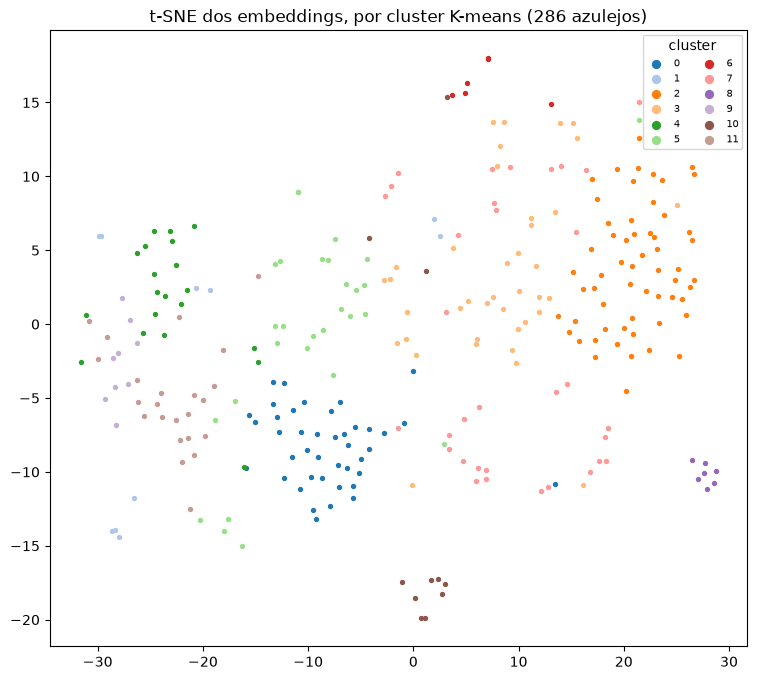

In [101]:
fig, ax = plt.subplots(figsize=(9, 8))
cmap = plt.get_cmap("tab20")
for k in sorted(set(clusters)):
    m = clusters == k
    ax.scatter(points[m, 0], points[m, 1], s=8, color=cmap(int(k) % 20), label=str(k))
ax.set_title(f"t-SNE dos embeddings, por cluster K-means ({len(ids)} azulejos)")
ax.legend(markerscale=2, fontsize=7, ncol=2, title="cluster")
plt.show()



In [ ]:
session = fo.launch_app(dataset)

The `show_confidence` App config option has been removed and no longer has any effect. Label attribute visibility is controlled per attribute in the App's sidebar
The `show_index` App config option has been removed and no longer has any effect. Label attribute visibility is controlled per attribute in the App's sidebar
The `show_confidence` App config option has been removed and no longer has any effect. Label attribute visibility is controlled per attribute in the App's sidebar
The `show_label` App config option has been removed and no longer has any effect. Label attribute visibility is controlled per attribute in the App's sidebar
The `show_index` App config option has been removed and no longer has any effect. Label attribute visibility is controlled per attribute in the App's sidebar
The `show_label` App config option has been removed and no longer has any effect. Label attribute visibility is controlled per attribute in the App's sidebar
The `show_confidence` App config option ha

In [ ]:
# plot_cluster = fo.scatterplot(
#     points,
#     samples=dataset,
#     ids=ids,
#     labels=[f"cluster {c}" for c in clusters],
#     title="t-SNE (DINOv2-small) · cor = cluster",
# )


### Unicidade


Outra forma de explorar os embeddings é através de entendermos quão diferente esse embedding é comparado a todos os outros. 

A **unicidade** responde essa pergunta pergunta, e o passo não é muito complicado:

1. Para cada azulejo, encontramos os **K = 10 vizinhos mais próximos** pela distância de cosseno (distância = 1 − similaridade).
2. Fazemos uma **média ponderada** dessas distâncias. Os vizinhos mais próximos pesam mais, com pesos exponenciais que caem a cada posição.
3. Dividimos pelo maior valor do conjunto, para que os valores fiquem entre 0 e 1. O azulejo mais isolado recebe **1.0**.




In [109]:
compute_uniqueness_field(dataset, embeddings=emb, sample_ids=ids, uniqueness_field=UNIQUENESS_FIELD,
                         k=K_NEIGHBOURS, decay="exponential", decay_param=0.5, save=True, verbose=True)
compute_uniqueness_field_v2(dataset, embeddings=emb, sample_ids=ids, uniqueness_field=UNIQUENESS_CLUSTER_FIELD,
                            cluster_field=CLUSTER_FIELD, k=K_NEIGHBOURS, decay="exponential", decay_param=0.5,
                            save=True, verbose=True)

summary = pd.DataFrame({
    "azulejos": pd.Series(clusters).value_counts().sort_index(),
    "cenas presentes": pd.Series(scene_ids).groupby(clusters).nunique(),
})
summary.index.name = "cluster"
display(summary)

  Using pre-loaded embeddings array: (286, 384) (286 sample_ids).
  Resolved 286 embeddings, dim=384
  Decay: exponential  param=0.5  k=10  weights=[0.607, 0.368, 0.223, 0.135, 0.082, 0.050, 0.030, 0.018, 0.011, 0.007]
  Fitting kNN (k=10, metric=cosine, N=286) ...
  Uniqueness stats: min=0.1057  mean=0.3442  max=1.0000
  Above 0.5: 50  |  above 0.9: 1  (out of 286)
  Writing field 'uniqueness_score' to dataset ...
 100% |█████████████████| 286/286 [183.1ms elapsed, 0s remaining, 1.6K samples/s]       
bum! Scores saved to 'uniqueness_score'.
  Using pre-loaded embeddings array: (286, 384) (286 sample_ids).
  Resolved 286 embeddings, dim=384
  Decay: exponential  param=0.5  k=10  weights=[0.607, 0.368, 0.223, 0.135, 0.082, 0.050, 0.030, 0.018, 0.011, 0.007]
  Loading cluster labels from 'cluster_kmeans_12' ...
 100% |█████████████████| 286/286 [77.6ms elapsed, 0s remaining, 3.7K samples/s] 
  Found 12 clusters.
DANGER  cluster 0: k_eff=10 >= sqrt(41)=6. Consider reducing k.
    cluster

,azulejos,cenas presentes
cluster,,
0,41,5
1,10,2
2,58,7
3,39,10
4,20,7
5,29,10
6,6,1
7,33,10
8,7,1


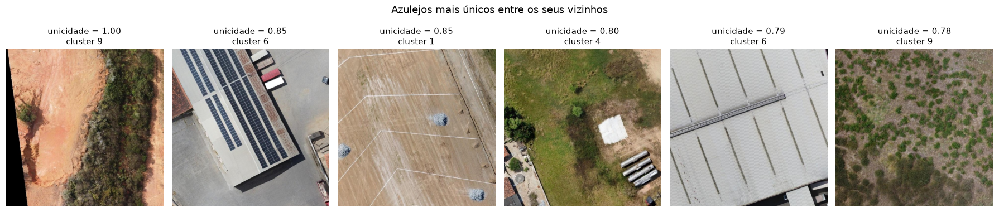

In [110]:
# Os 6 azulejos mais únicos do conjunto
uniq = np.array(dataset.values(UNIQUENESS_FIELD), dtype=float)
top = np.argsort(-uniq)[:6]

fig, axes = plt.subplots(1, 6, figsize=(18, 3.9))
for ax, idx in zip(axes, top):
    ax.imshow(Image.open(tile_previews[idx]))
    ax.set_title(f"unicidade = {uniq[idx]:.2f}\ncluster {clusters[idx]}", fontsize=11)
    ax.axis("off")
fig.suptitle("Azulejos mais únicos entre os seus vizinhos", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

## O que fazer com esses conceitos? 

Essa aula foi para elencar como os modelos fundacionais podem ser utilizados para extraírmos informações importante de nossos datasets. 

Esta aula parou na exploração dos embeddings. Os próximos passos possíveis são:

- verificar como o modelo se sai **sem fine-tuning** nas nossas cenas, ou seja, qual seria o desempenho dele sem treinar nada novo;
- rotular algumas cenas e fazer o **fine-tuning** do modelo com esses rótulos.